<a href="https://colab.research.google.com/github/jc2727/Chatbot_intenciones_reglas/blob/main/avance_dos_imagenes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#Descargar las imagenes necesarias para entrenar el modelo
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="4abeSw1VnWz3n2klFIdy")
project = rf.workspace("juan-martinez-bl3dr").project("smart-retail-988-mqc6h")
version = project.version(1)
dataset = version.download("folder")



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 24.8 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [roboflow]
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Smart-Retail-988-1 in folder:: 100%|██████████| 5423/5423 [00:00<00:00, 7373.13it/s]


In [3]:
#REvisar donde están guardadas las imagenes
import os

print(dataset.location)
print(os.listdir(dataset.location))



/content/Smart-Retail-988-1
['README.roboflow.txt', 'test', 'train', 'valid']


In [4]:
#Validar que tiene la carpeta y las clases, asegurando que tengan labels y la imagen
from pathlib import Path

ruta = Path("/content/Smart-Retail-988-1")

for split in ["train", "valid", "test"]:
    carpeta = ruta / split

    print(f"\n{split.upper()}")
    print("Contenido:", [p.name for p in carpeta.iterdir()][:20])


TRAIN
Contenido: ['Arla-Sour-Milk', 'Sweet-Potato', 'Tropicana-Apple-Juice', 'Plum', 'Vine-Tomato', 'Satsumas', 'Red-Bell-Pepper', 'Red-Delicious', 'Kiwi', 'Green-Bell-Pepper', 'Garant-Ecological-Medium-Fat-Milk', 'Orange', 'Lemon', 'Solid-Potato', 'Mango', 'Ginger', 'Tropicana-Golden-Grapefruit', 'Tropicana-Juice-Smooth', 'God-Morgon-Orange-Red-Grapefruit-Juice', 'Brown-Cap-Mushroom']

VALID
Contenido: ['Arla-Sour-Milk', 'Sweet-Potato', 'Tropicana-Apple-Juice', 'Plum', 'Vine-Tomato', 'Satsumas', 'Red-Bell-Pepper', 'Red-Delicious', 'Kiwi', 'Green-Bell-Pepper', 'Garant-Ecological-Medium-Fat-Milk', 'Orange', 'Lemon', 'Solid-Potato', 'Mango', 'Ginger', 'Tropicana-Golden-Grapefruit', 'Tropicana-Juice-Smooth', 'God-Morgon-Orange-Red-Grapefruit-Juice', 'Brown-Cap-Mushroom']

TEST
Contenido: ['Arla-Sour-Milk', 'Sweet-Potato', 'Tropicana-Apple-Juice', 'Plum', 'Vine-Tomato', 'Satsumas', 'Red-Bell-Pepper', 'Red-Delicious', 'Kiwi', 'Green-Bell-Pepper', 'Garant-Ecological-Medium-Fat-Milk', 'Orang

In [5]:

#Contemos cuantas imagenes tenemos de algunas clases, por simplicidad me quedaré solo con 4


clases = [
    "Satsumas",
    "Granny-Smith",
    "Royal-Gala",
    "Orange"
]

total = 0

for split in ["train", "valid", "test"]:
    print(f"\n{split.upper()}")

    for clase in clases:
        carpeta = ruta / split / clase

        if carpeta.exists():
            imagenes = [
                p for p in carpeta.iterdir()
                if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
            ]

            cantidad = len(imagenes)
            total += cantidad

            print(f"{clase}: {cantidad}")
        else:
            print(f"{clase}: NO ENCONTRADA")

print(f"\nTotal de imágenes: {total}")


TRAIN
Satsumas: 95
Granny-Smith: 88
Royal-Gala: 100
Orange: 73

VALID
Satsumas: 36
Granny-Smith: 23
Royal-Gala: 21
Orange: 33

TEST
Satsumas: 12
Granny-Smith: 12
Royal-Gala: 13
Orange: 12

Total de imágenes: 518


In [6]:
#Verificar que estemos usando CUDA para más rápido
import torch
from torch import nn
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Dispositivo:", device)

Dispositivo: cuda


In [7]:
#Preparar datasets de train y de eval, haciendo redimensionamiento y aumentando las imagenes de training
#con rotación para tener más.

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [8]:
clases = [
    "Granny-Smith",
    "Orange",
    "Royal-Gala",
    "Satsumas"
]

def cargar_frutas(ruta,split,clases,transform):

  dataset = datasets.ImageFolder(
      str(ruta / split),
      transform=transform
  )

  muestras = []

  for imagen, etiqueta_original in dataset.samples:

    nombre = dataset.classes[etiqueta_original]

    if nombre in clases:
      etiqueta = clases.index(nombre)
      muestras.append((imagen, etiqueta))

  dataset.samples = muestras
  dataset.imgs = muestras
  dataset.targets = [etiqueta for _, etiqueta in muestras]
  dataset.classes = clases
  dataset.class_to_idx = {
      nombre: i for i, clase in enumerate(clases)
  }

  return dataset


train_data = cargar_frutas(
    ruta,
    "train",
    clases,
    train_transform
)

valid_data = cargar_frutas(
    ruta,
    "valid",
    clases,
    eval_transform
)

test_data = cargar_frutas(
    ruta,
    "test",
    clases,
    eval_transform
)

print("Train:", len(train_data))
print("Valid:", len(valid_data))
print("Test:", len(test_data))

Train: 356
Valid: 113
Test: 49


In [9]:
#Definir Dataloaders para crear lotes pequeños
train_loader = DataLoader(
    train_data,
    batch_size=16,
    shuffle=True
)

valid_loader = DataLoader(
    valid_data,
    batch_size=16,
    shuffle=False
)

test_loader = DataLoader(
    test_data,
    batch_size=16,
    shuffle=False
)

In [10]:
from torchvision.models import resnet50, ResNet50_Weights
import torch.nn as nn

# ResNet50 preentrenado con ImageNet
modelo = resnet50(
    weights=ResNet50_Weights.DEFAULT
)

# Congelar las capas preentrenadas
for parametro in modelo.parameters():
    parametro.requires_grad = False

# Sustituir la capa final para clasificar 4 frutas
modelo.fc = nn.Linear(
    modelo.fc.in_features,
    4
)

# Enviar modelo a GPU
modelo = modelo.to(device)

print("ResNet50 listo")
print("Capa final:", modelo.fc)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 175MB/s]


ResNet50 listo
Capa final: Linear(in_features=2048, out_features=4, bias=True)


In [11]:
#Definir la funcion de cross entropy y el optimizador adam,
#El learning rate será un defautl de .001 por ahora
import torch.optim as optim

criterio = nn.CrossEntropyLoss()

optimizador = optim.Adam(
    modelo.fc.parameters(),
    lr=0.001
)

epochs = 10

In [12]:
historial = {
    "train_loss": [],
    "train_acc": [],
    "valid_loss": [],
    "valid_acc": []
}

for epoch in range(epochs):

    # Entrenamiento
    modelo.train()
    train_loss = 0
    train_correct = 0

    for imagenes, etiquetas in train_loader:
        imagenes = imagenes.to(device)
        etiquetas = etiquetas.to(device)

        optimizador.zero_grad()

        salidas = modelo(imagenes)
        loss = criterio(salidas, etiquetas)

        loss.backward()
        optimizador.step()

        train_loss += loss.item() * imagenes.size(0)
        train_correct += (
            salidas.argmax(1) == etiquetas
        ).sum().item()

    # Validación
    modelo.eval()
    valid_loss = 0
    valid_correct = 0

    with torch.no_grad():
        for imagenes, etiquetas in valid_loader:
            imagenes = imagenes.to(device)
            etiquetas = etiquetas.to(device)

            salidas = modelo(imagenes)
            loss = criterio(salidas, etiquetas)

            valid_loss += loss.item() * imagenes.size(0)
            valid_correct += (
                salidas.argmax(1) == etiquetas
            ).sum().item()

    train_acc = train_correct / len(train_data)
    valid_acc = valid_correct / len(valid_data)

    train_loss /= len(train_data)
    valid_loss /= len(valid_data)

    historial["train_loss"].append(train_loss)
    historial["train_acc"].append(train_acc)
    historial["valid_loss"].append(valid_loss)
    historial["valid_acc"].append(valid_acc)

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Acc: {train_acc:.2%} | "
        f"Valid Acc: {valid_acc:.2%}"
    )

Epoch 1/10 | Train Acc: 56.74% | Valid Acc: 68.14%
Epoch 2/10 | Train Acc: 81.74% | Valid Acc: 84.96%
Epoch 3/10 | Train Acc: 86.52% | Valid Acc: 89.38%
Epoch 4/10 | Train Acc: 92.42% | Valid Acc: 86.73%
Epoch 5/10 | Train Acc: 90.45% | Valid Acc: 90.27%
Epoch 6/10 | Train Acc: 90.17% | Valid Acc: 86.73%
Epoch 7/10 | Train Acc: 91.57% | Valid Acc: 87.61%
Epoch 8/10 | Train Acc: 92.70% | Valid Acc: 89.38%
Epoch 9/10 | Train Acc: 94.38% | Valid Acc: 91.15%
Epoch 10/10 | Train Acc: 94.10% | Valid Acc: 91.15%


Accuracy: 0.9387755102040817

Reporte de clasificación:
              precision    recall  f1-score   support

Granny-Smith       1.00      1.00      1.00        12
      Orange       0.91      0.83      0.87        12
  Royal-Gala       1.00      1.00      1.00        13
    Satsumas       0.85      0.92      0.88        12

    accuracy                           0.94        49
   macro avg       0.94      0.94      0.94        49
weighted avg       0.94      0.94      0.94        49

Matriz de confusión:
[[12  0  0  0]
 [ 0 10  0  2]
 [ 0  0 13  0]
 [ 0  1  0 11]]


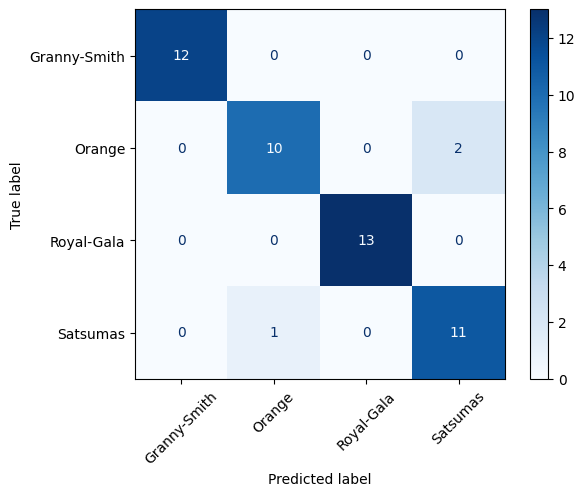

In [20]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

modelo.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for imagenes, etiquetas in test_loader:
        imagenes = imagenes.to(device)

        salidas = modelo(imagenes)
        predicciones = salidas.argmax(1)

        y_true.extend(etiquetas.numpy())
        y_pred.extend(predicciones.cpu().numpy())

print("Accuracy:", accuracy_score(y_true, y_pred))

print("\nReporte de clasificación:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(len(clases))),
        target_names=clases,
        zero_division=0
    )
)



matriz = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(clases)))
)

print("Matriz de confusión:")
print(matriz)

# Agregamos 'display_labels=clases' para que dibuje los nombres de las frutas en los ejes
ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=list(range(len(clases))),
    display_labels=clases,
    xticks_rotation=45,
    cmap="Blues"
)

plt.show()


In [ ]:
#Guardaré el modelo para usar con mi chatbot

torch.save(modelo.state_dict(), "resnet_frutas.pth")

In [2]:
# 1. Comprimir la carpeta en un archivo zip
!zip -r smart_retail.zip /content/Smart-Retail-988-1

# 2. Descargar el archivo zip a tu computadora
from google.colab import files
files.download('smart_retail.zip')

Se truncaron las últimas líneas 5000 del resultado de transmisión.
  adding: content/Smart-Retail-988-1/train/Sweet-Potato/Sweet-Potato_001_jpg.rf.d16c3cbbdcafa8cbcaf952fed02b5c8e.jpg (deflated 1%)
  adding: content/Smart-Retail-988-1/train/Sweet-Potato/Sweet-Potato_009_jpg.rf.f2f8d20c7961eacb6c1c92ea320738a3.jpg (deflated 1%)
  adding: content/Smart-Retail-988-1/train/Sweet-Potato/Sweet-Potato_006_jpg.rf.4f71e5ab8c33c76bbc000a383e47c608.jpg (deflated 1%)
  adding: content/Smart-Retail-988-1/train/Sweet-Potato/Sweet-Potato_002_jpg.rf.23ff339ec5d18a6835a75947403b479c.jpg (deflated 1%)
  adding: content/Smart-Retail-988-1/train/Sweet-Potato/Sweet-Potato_011_jpg.rf.5f605b977ca6e4fe617971ce2df5a78e.jpg (deflated 1%)
  adding: content/Smart-Retail-988-1/train/Sweet-Potato/Sweet-Potato_026_jpg.rf.4b9a8be5c03e37413e9a5fa1a7dcf309.jpg (deflated 1%)
  adding: content/Smart-Retail-988-1/train/Sweet-Potato/Sweet-Potato_008_jpg.rf.c94a17598e300c2dfffa48d787b22356.jpg (deflated 1%)
  adding: conten

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>